# Truck Turnaround Time (TAT) Analysis and Reduction in Warehouse Operations




### Import Libraries

We import beginner-friendly Python libraries for data analytics and visualization. We also configure clear visualization styles (clean grids, legible font sizes, and distinct palettes) to ensure all generated charts look executive-ready.


In [2]:
# Import core analytics and plotting libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load Datasets

We load the four core CSV datasets using relative file paths so that the project runs seamlessly in any local folder:



In [3]:
# Load all four CSV datasets using relative paths
df_tat = pd.read_csv(r"truck_visit_data.csv")
df_warehouse = pd.read_csv(r"datasets\warehouse_master.csv")
df_transporter = pd.read_csv(r"datasets\transporter_master.csv")
df_dock = pd.read_csv(r"datasets\dock_master.csv")

print("All four CSV datasets successfully loaded into Pandas DataFrames.")


All four CSV datasets successfully loaded into Pandas DataFrames.


In [4]:
# Display dimensions (rows, columns) of each dataset
print(f"Truck TAT Transactional Data Shape : {df_tat.shape} (Rows, Columns)")
print(f"Warehouse Master Shape              : {df_warehouse.shape}")
print(f"Transporter Master Shape            : {df_transporter.shape}")
print(f"Dock Master Shape                   : {df_dock.shape}")


Truck TAT Transactional Data Shape : (2500, 25) (Rows, Columns)
Warehouse Master Shape              : (4, 5)
Transporter Master Shape            : (6, 4)
Dock Master Shape                   : (15, 4)


In [5]:
# Display the first five rows of the primary transactional dataset
pd.set_option('display.max_columns', None)
df_tat.head(3)


,truck_visit_id,truck_number,arrival_date,arrival_month,arrival_hour,warehouse_id,transporter_id,dock_id,arrival_time,dock_assigned_time,loading_start_time,loading_end_time,documentation_complete_time,exit_time,gate_to_dock_min,dock_wait_min,loading_unloading_min,documentation_min,total_tat_hours,tat_status,truck_type,load_tons,cases_handled,arrival_shift,primary_delay_reason
0,TRK00001,JH89M7294,04-04-2026,2026-04,8,WH04,TRP02,D03,04-04-2026 08:17,04-04-2026 08:35,04-04-2026 08:49,04-04-2026 10:09,04-04-2026 10:37,04-04-2026 10:43,18,14,80,28,2.43,On Target,Medium,8.85,755,Morning,No Major Delay
1,TRK00002,OD04L3293,04-04-2026,2026-04,8,WH03,TRP06,D05,04-04-2026 08:22,04-04-2026 08:39,04-04-2026 08:48,04-04-2026 09:35,04-04-2026 10:00,04-04-2026 10:08,17,9,47,25,1.77,On Target,Medium,5.54,420,Morning,No Major Delay
2,TRK00003,JH12N6035,04-04-2026,2026-04,9,WH01,TRP05,D01,04-04-2026 09:01,04-04-2026 09:23,04-04-2026 09:33,04-04-2026 12:13,04-04-2026 12:45,04-04-2026 12:54,22,10,160,32,3.88,Delayed,Heavy,18.54,1459,Morning,Equipment Delay


In [6]:
# Display the master reference tables
print("--- WAREHOUSE MASTER ---")
display(df_warehouse)

print("\n--- TRANSPORTER MASTER ---")
display(df_transporter)

print("\n--- DOCK MASTER (First 5 Rows) ---")
display(df_dock.head())


--- WAREHOUSE MASTER ---


,warehouse_id,warehouse_name,city,region,number_of_docks
0,WH01,Jamshedpur Central Warehouse,Jamshedpur,East,4
1,WH02,Ranchi Distribution Warehouse,Ranchi,East,3
2,WH03,Kolkata Regional Warehouse,Kolkata,East,5
3,WH04,Patna Distribution Warehouse,Patna,East,3



--- TRANSPORTER MASTER ---


,transporter_id,transporter_name,contract_type,fleet_category
0,TRP01,Alpha Logistics,Contract,Large Fleet
1,TRP02,Bharat Roadways,Contract,Medium Fleet
2,TRP03,CityLink Transport,Spot,Medium Fleet
3,TRP04,Eastern Cargo Movers,Contract,Large Fleet
4,TRP05,FastTrack Carriers,Spot,Small Fleet
5,TRP06,National Freight Services,Contract,Large Fleet



--- DOCK MASTER (First 5 Rows) ---


,dock_id,warehouse_id,dock_name,dock_type
0,WH01_D01,WH01,Dock 01,Inbound
1,WH01_D02,WH01,Dock 02,Outbound
2,WH01_D03,WH01,Dock 03,Inbound
3,WH01_D04,WH01,Dock 04,Outbound
4,WH02_D01,WH02,Dock 01,Inbound


### Understanding Raw Data



In [7]:
# Inspect column names, non-null counts, and data types
df_tat.info()


<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   truck_visit_id               2500 non-null   str    
 1   truck_number                 2500 non-null   str    
 2   arrival_date                 2500 non-null   str    
 3   arrival_month                2500 non-null   str    
 4   arrival_hour                 2500 non-null   int64  
 5   warehouse_id                 2500 non-null   str    
 6   transporter_id               2500 non-null   str    
 7   dock_id                      2500 non-null   str    
 8   arrival_time                 2500 non-null   str    
 9   dock_assigned_time           2500 non-null   str    
 10  loading_start_time           2500 non-null   str    
 11  loading_end_time             2500 non-null   str    
 12  documentation_complete_time  2500 non-null   str    
 13  exit_time                    

In [8]:
df_tat.shape

(2500, 25)

In [9]:
# Check for exact duplicate records in the transactional dataset
duplicate_rows = df_tat.duplicated().sum()
print(f"Total Duplicate Records Found: {duplicate_rows}")


Total Duplicate Records Found: 0


In [10]:
# Check for missing (null) values across all columns
missing_values = df_tat.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found across columns.")


Missing values per column:
No missing values found across columns.


In [11]:
# Statistical summary of numerical columns in the raw data
df_tat.describe().round(2)


,arrival_hour,gate_to_dock_min,dock_wait_min,loading_unloading_min,documentation_min,total_tat_hours,load_tons,cases_handled
count,2500.0,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00,2500.00
mean,12.3,22.64,83.95,111.57,32.57,4.32,15.10,1199.35
std,2.6,13.45,86.89,39.35,13.60,1.65,5.85,467.09
min,8.0,8.00,7.00,35.00,14.00,1.45,3.00,212.00
25%,10.0,15.00,17.00,82.00,25.00,3.15,10.54,835.00
50%,12.0,19.00,59.00,109.00,29.00,4.02,14.78,1182.50
75%,14.0,25.00,120.00,139.00,35.00,5.12,19.84,1563.00
max,19.0,142.00,610.00,265.00,116.00,13.30,28.00,2377.00


### Raw Data Assessment Summary:
1. **Data Types:** All timestamp columns (`arrival_time`, `dock_assigned_time`, `loading_start_time`, `loading_end_time`, `documentation_complete_time`, `exit_time`) are stored as strings (`object` type). They must be converted to datetime objects to perform time arithmetic.
2. **Missing & Duplicate Values:** The dataset contains 2,500 complete records with zero null values and zero duplicate rows.



### Data Cleaning and Validations



In [12]:
#  Create an isolated working copy of the raw dataset
df_clean = df_tat.copy()
df_clean = df_clean.drop_duplicates()

# Convert all milestone timestamp columns to proper datetime format
timestamp_columns = [
    'arrival_time', 
    'dock_assigned_time', 
    'loading_start_time', 
    'loading_end_time', 
    'documentation_complete_time', 
    'exit_time'
]


for col in timestamp_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], format='%d-%m-%Y %H:%M', errors='coerce')





#### validation 1

Check chronological milestone sequences

arrival_time <= dock_assigned_time <= loading_start_time <= loading_end_time <= documentation_complete_time <= exit_time


In [13]:
invalid_sequence = (
    (df_clean['arrival_time'] > df_clean['dock_assigned_time']) |
    (df_clean['dock_assigned_time'] > df_clean['loading_start_time']) |
    (df_clean['loading_start_time'] > df_clean['loading_end_time']) |
    (df_clean['loading_end_time'] > df_clean['documentation_complete_time']) |
    (df_clean['documentation_complete_time'] > df_clean['exit_time'])
)

print(f"Total records with chronological sequencing errors: {invalid_sequence.sum()}")


Total records with chronological sequencing errors: 0


#### validation 2

Check for negative or impossible stage durations

In [14]:

negative_durations = (
    (df_clean['gate_to_dock_min'] < 0) |
    (df_clean['dock_wait_min'] < 0) |
    (df_clean['loading_unloading_min'] < 0) |
    (df_clean['documentation_min'] < 0) |
    (df_clean['total_tat_hours'] < 0)
)

print(f"Total records with negative stage durations: {negative_durations.sum()}")


Total records with negative stage durations: 0


#### validation 3

Recalculate Total TAT directly from arrival and exit timestamps

Compare calculated TAT with the existing raw total_tat_hours column

In [15]:

# Recalculate TAT in minutes and hours
df_clean['calculated_tat_min'] = ((df_clean['exit_time'] - df_clean['arrival_time']).dt.total_seconds() / 60).round(1)
df_clean['calculated_tat_hours'] = (df_clean['calculated_tat_min'] / 60).round(2)
 
tat_discrepancy = (df_clean['calculated_tat_hours'] - df_clean['total_tat_hours']).abs().max()
assert tat_discrepancy < 0.05, f"TAT mismatch found: {tat_discrepancy} hours"
print(f"TAT validation passed (max discrepancy: {tat_discrepancy} hours)")


TAT validation passed (max discrepancy: 0.0 hours)


Outlier detection using Interquartile Range (IQR) method

In [16]:
Q1 = df_clean['calculated_tat_hours'].quantile(0.25)
Q3 = df_clean['calculated_tat_hours'].quantile(0.75)
IQR = Q3 - Q1
upper_whisker = Q3 + 1.5 * IQR

df_clean['is_tat_outlier'] = df_clean['calculated_tat_hours'] > upper_whisker

print(f"Q1 (25th percentile)              : {Q1:.2f} hours ({Q1*60:.0f} mins)")
print(f"Q3 (75th percentile)              : {Q3:.2f} hours ({Q3*60:.0f} mins)")
print(f"IQR (Interquartile Range)         : {IQR:.2f} hours ({IQR*60:.0f} mins)")
print(f"Upper Outlier Threshold (Q3+1.5IQR): {upper_whisker:.2f} hours ({upper_whisker*60:.0f} mins)")
print(f"Number of Flagged High-TAT Trips  : {df_clean['is_tat_outlier'].sum()} ({df_clean['is_tat_outlier'].mean()*100:.2f}% of trips)")


Q1 (25th percentile)              : 3.15 hours (189 mins)
Q3 (75th percentile)              : 5.12 hours (307 mins)
IQR (Interquartile Range)         : 1.97 hours (118 mins)
Upper Outlier Threshold (Q3+1.5IQR): 8.07 hours (484 mins)
Number of Flagged High-TAT Trips  : 82 (3.28% of trips)


Create / update useful columns

Benchmark compliance against assumed 3.0-hour SLA target

In [17]:

df_clean['benchmark_compliance'] = np.where(
    df_clean['calculated_tat_hours'] <= 3.0, 
    'Within Benchmark (<= 3 Hrs)', 
    'Exceeded Benchmark (> 3 Hrs)'
)

print("Compliance Distribution:")
print(df_clean['benchmark_compliance'].value_counts(normalize=True).round(4) * 100)


Compliance Distribution:
benchmark_compliance
Exceeded Benchmark (> 3 Hrs)    78.92
Within Benchmark (<= 3 Hrs)     21.08
Name: proportion, dtype: float64


In [18]:
# Display dataset after cleaning (first 3 rows)
df_clean[['truck_visit_id', 'warehouse_id', 'transporter_id', 'arrival_time', 'exit_time', 
          'calculated_tat_min', 'calculated_tat_hours', 'benchmark_compliance', 'is_tat_outlier']].head(3)


,truck_visit_id,warehouse_id,transporter_id,arrival_time,exit_time,calculated_tat_min,calculated_tat_hours,benchmark_compliance,is_tat_outlier
0,TRK00001,WH04,TRP02,2026-04-04 08:17:00,2026-04-04 10:43:00,146.0,2.43,Within Benchmark (<= 3 Hrs),False
1,TRK00002,WH03,TRP06,2026-04-04 08:22:00,2026-04-04 10:08:00,106.0,1.77,Within Benchmark (<= 3 Hrs),False
2,TRK00003,WH01,TRP05,2026-04-04 09:01:00,2026-04-04 12:54:00,233.0,3.88,Exceeded Benchmark (> 3 Hrs),False


In [19]:

#  DELETE: duplicate / unused columns 
drop_cols = ['total_tat_hours', 'calculated_tat_min', 'tat_status', 'truck_number']
df_clean = df_clean.drop(columns=drop_cols, errors='ignore')

# ADD: peak-hour flag 
df_clean['is_peak'] = df_clean['arrival_hour'].isin([10, 11, 14, 15])

# ADD: weekday 
df_clean['arrival_weekday'] = df_clean['arrival_time'].dt.day_name()

# Save
df_clean.to_csv("cleaned_truck_tat_data.csv", index=False)

---
## Exploratory Data Analysis (EDA)

Having verified data hygiene and calculated true operational metrics, we conduct exploratory data analysis to answer eight crucial warehouse management questions:
1. Overall TAT Analysis & SLA Target Adherence
2. TAT Distribution Shape
3. Month-over-Month TAT Trend
4. Stage-wise Delay Breakdown
5. Warehouse Facility Performance
6. Peak Arrival Gate Hours
7. Delay Root-Cause Analysis
8. Transporter Compliance Performance


### Analysis 1: Overall TAT Statistical Profile
**Business Question:** What is the average turnaround time across the warehouse network, and what percentage of trucks meet our assumed 3.0-hour turnaround target?


In [20]:
# Compute summary statistical metrics
mean_tat = df_clean['calculated_tat_hours'].mean()
median_tat = df_clean['calculated_tat_hours'].median()
std_tat = df_clean['calculated_tat_hours'].std()
min_tat = df_clean['calculated_tat_hours'].min()
max_tat = df_clean['calculated_tat_hours'].max()
within_3h_count = (df_clean['calculated_tat_hours'] <= 3.0).sum()
within_3h_pct = (within_3h_count / len(df_clean)) * 100

print("=" * 60)
print("             NETWORK TRUCK TAT STATISTICAL SUMMARY")
print("=" * 60)
print(f"Total Truck Visits Evaluated : {len(df_clean):,}")
print(f"Mean Turnaround Time (TAT)   : {mean_tat:.2f} Hours ({mean_tat*60:.1f} Mins)")
print(f"Median Turnaround Time (TAT) : {median_tat:.2f} Hours ({median_tat*60:.1f} Mins)")
print(f"Standard Deviation           : {std_tat:.2f} Hours ({std_tat*60:.1f} Mins)")
print(f"Minimum Recorded TAT         : {min_tat:.2f} Hours ({min_tat*60:.1f} Mins)")
print(f"Maximum Recorded TAT         : {max_tat:.2f} Hours ({max_tat*60:.1f} Mins)")
print(f"Compliant Trips (<= 3.0 Hrs) : {within_3h_count:,} out of {len(df_clean):,} ({within_3h_pct:.2f}%)")
print(f"Breached Trips (> 3.0 Hrs)   : {len(df_clean) - within_3h_count:,} ({100 - within_3h_pct:.2f}%)")
print("=" * 60)


             NETWORK TRUCK TAT STATISTICAL SUMMARY
Total Truck Visits Evaluated : 2,500
Mean Turnaround Time (TAT)   : 4.32 Hours (259.3 Mins)
Median Turnaround Time (TAT) : 4.02 Hours (241.2 Mins)
Standard Deviation           : 1.65 Hours (99.1 Mins)
Minimum Recorded TAT         : 1.45 Hours (87.0 Mins)
Maximum Recorded TAT         : 13.30 Hours (798.0 Mins)
Compliant Trips (<= 3.0 Hrs) : 527 out of 2,500 (21.08%)
Breached Trips (> 3.0 Hrs)   : 1,973 (78.92%)


**Business Insight:**
* The network average turnaround time is **4.32 hours (259 minutes)**, and the median is **4.02 hours (241 minutes)**.
* **Only 21.08% of trucks (527 of 2,500) satisfy the assumed 3.0-hour target**, meaning **78.92% (1,973 trucks)** exceed it.
* The mean sits above the median and the standard deviation is large (1.65 hours), which shows that a group of very slow visits (up to 13.30 hours) pulls the average up. This points to dock queues on busy days rather than an equal delay on every trip (see Analysis 7 and the optimisation model).


### Analysis 2: Turnaround Time Distribution
**Business Question:** How is truck dwell time distributed across the fleet, and how far does actual performance deviate from the 3-hour benchmark?


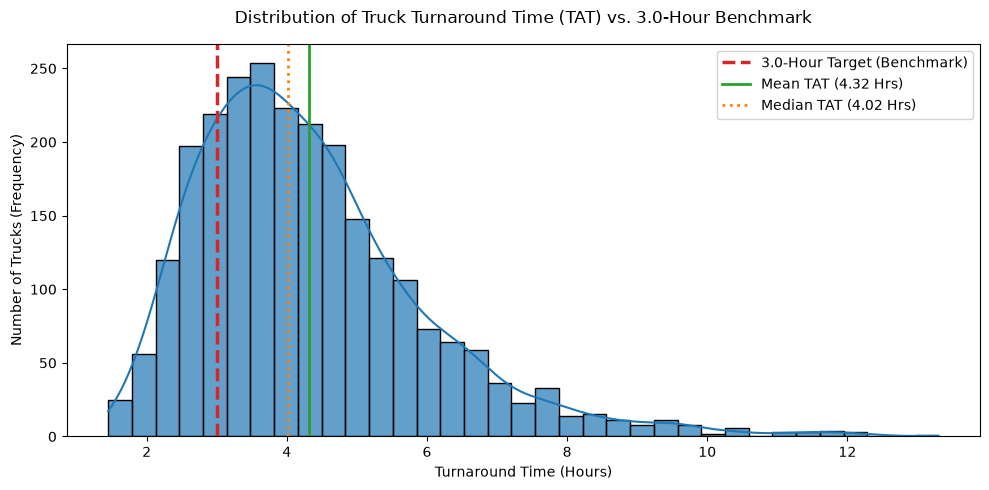

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['calculated_tat_hours'], bins=35, kde=True, color='#1f77b4', edgecolor='black', alpha=0.7)

# Overlay reference lines for benchmark, mean, and median
plt.axvline(3.0, color='#d62728', linestyle='--', linewidth=2.5, label='3.0-Hour Target (Benchmark)')
plt.axvline(mean_tat, color='#2ca02c', linestyle='-', linewidth=2, label=f'Mean TAT ({mean_tat:.2f} Hrs)')
plt.axvline(median_tat, color='#ff7f0e', linestyle=':', linewidth=2, label=f'Median TAT ({median_tat:.2f} Hrs)')

plt.title('Distribution of Truck Turnaround Time (TAT) vs. 3.0-Hour Benchmark', pad=15)
plt.xlabel('Turnaround Time (Hours)')
plt.ylabel('Number of Trucks (Frequency)')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


**Business Insight:**
* The turnaround distribution is **right-skewed** (skewness 1.29): the most common value is around **3.5 hours**, the median is 4.02 hours and a long tail stretches up to **13.30 hours**.
* **65.0%** of trucks spend between 3.0 and 6.0 hours inside the warehouse, and **13.9%** spend more than 6 hours. Only the left edge of the distribution (21.1% of trucks) falls inside the 3.0-hour target.
* By the IQR rule the upper whisker is **8.07 hours**, which flags **82 trips (3.28%)**. All 82 flagged trips were logged as Dock Congestion and waited **371 minutes** on average at the dock, so the extreme tail is a queueing problem.


### Analysis 3: Monthly Performance Trend
**Business Question:** Has truck turnaround time improved, remained flat, or deteriorated over the 6-month period (April to September 2026)?


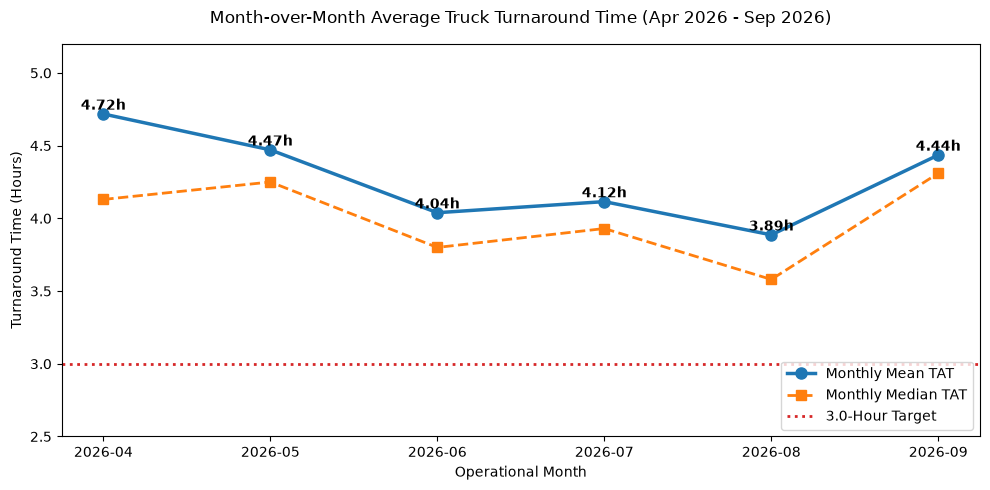

In [22]:
monthly_perf = df_clean.groupby('arrival_month')['calculated_tat_hours'].agg(['mean', 'median', 'count']).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_perf['arrival_month'], monthly_perf['mean'], marker='o', linewidth=2.5, markersize=8, color='#1f77b4', label='Monthly Mean TAT')
plt.plot(monthly_perf['arrival_month'], monthly_perf['median'], marker='s', linewidth=2.0, markersize=7, color='#ff7f0e', linestyle='--', label='Monthly Median TAT')
plt.axhline(3.0, color='#d62728', linestyle=':', linewidth=2, label='3.0-Hour Target')

for x, y in zip(monthly_perf['arrival_month'], monthly_perf['mean']):
    plt.text(x, y + 0.03, f"{y:.2f}h", ha='center', fontweight='bold', fontsize=10)

plt.title('Month-over-Month Average Truck Turnaround Time (Apr 2026 - Sep 2026)', pad=15)
plt.xlabel('Operational Month')
plt.ylabel('Turnaround Time (Hours)')
plt.ylim(2.5, 5.2)
plt.legend(loc='lower right', frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


**Business Insight:**
* Monthly average TAT moves between **3.89 hours (August)** and **4.72 hours (April)**, with September (4.44) and May (4.47) also high. The median follows the same pattern.
* The variation follows the **volume handled on the sampled operating days**: April had about 72 trucks per day against about 48 in August, and monthly dock wait moves with it (108 min in April, 61 min in August). Busier days mean longer queues.
* Every month stays well above the 3.0-hour target, so there is no month in which the network meets the benchmark. Each month is based on only 7 sampled operating days, so the month-to-month ranking should be read as a volume effect, not as a trend of improvement or deterioration.


### Analysis 4: Stage-wise Delay Breakdown
**Business Question:** In which operational sub-stage do trucks lose the most time inside the warehouse?


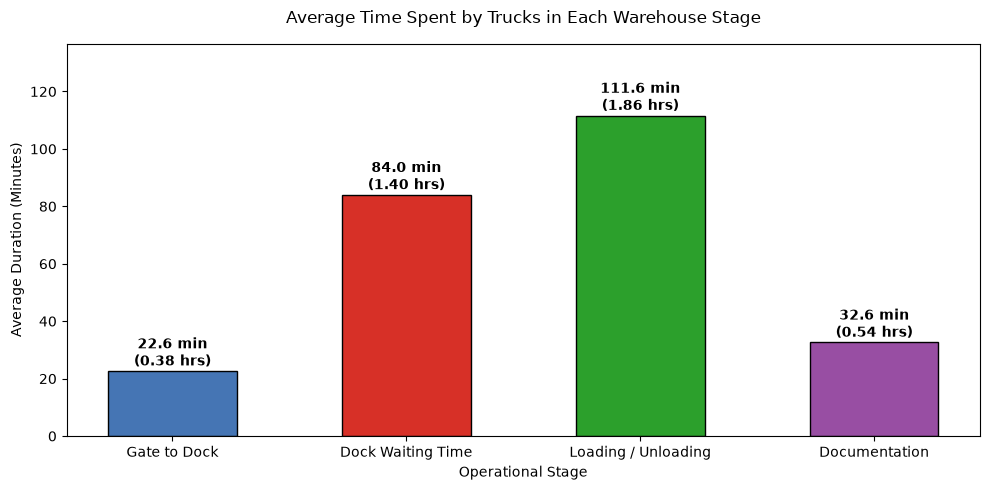

In [23]:
stage_averages = pd.Series({
    'Gate to Dock': df_clean['gate_to_dock_min'].mean(),
    'Dock Waiting Time': df_clean['dock_wait_min'].mean(),
    'Loading / Unloading': df_clean['loading_unloading_min'].mean(),
    'Documentation': df_clean['documentation_min'].mean()
}).round(1)

plt.figure(figsize=(10, 5))
stage_colors = ['#4575b4', '#d73027', '#2ca02c', '#984ea3']
bars = plt.bar(stage_averages.index, stage_averages.values, color=stage_colors, edgecolor='black', width=0.55)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 2.0, f"{h:.1f} min\n({h/60:.2f} hrs)", ha='center', fontweight='bold')

plt.title('Average Time Spent by Trucks in Each Warehouse Stage', pad=15)
plt.xlabel('Operational Stage')
plt.ylabel('Average Duration (Minutes)')
plt.ylim(0, stage_averages.max() + 25)
plt.tight_layout()
plt.show()


**Business Insight:**
* **Loading/Unloading (111.6 minutes / 1.86 hours, 43% of TAT)** and **Dock Waiting Time (84.0 minutes / 1.40 hours, 32% of TAT)** are the two largest contributors, together consuming **195.5 minutes (3.26 hours)**, which already exceeds the entire 3.0-hour turnaround target.
* **Dock waiting (84.0 min)** is the largest non-value-added stage: the truck is in the yard or at its bay but material handling has not started. **49.4% of trucks wait more than 60 minutes**, and dock wait alone has a 0.88 correlation with total TAT, so it explains most of the difference between a fast and a slow visit. The dock analysis in the optimisation section shows that the main cause is a queue behind a dock that is still occupied.
* **Gate-to-Dock (22.6 minutes, 9%)**, **Documentation (32.6 minutes, 13%)** and **Gate Exit (8.6 minutes, 3%)** are much smaller, so gate and paperwork improvements alone cannot close the gap to 3.0 hours.


### Analysis 5: Warehouse-wise Performance Comparison
**Business Question:** How does turnaround performance compare across regional warehouse facilities?


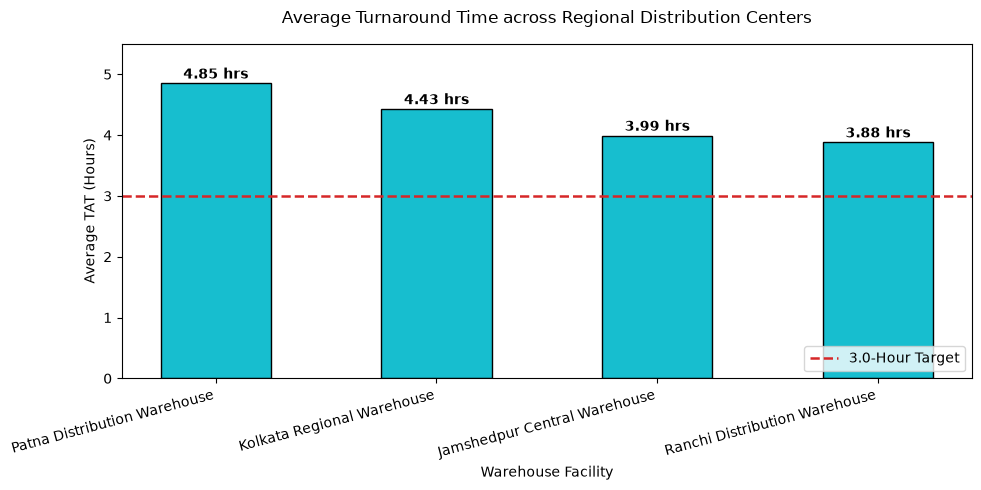

In [24]:
wh_merged = df_clean.merge(df_warehouse, on='warehouse_id', how='left')
wh_comparison = wh_merged.groupby(['warehouse_id', 'warehouse_name', 'city'])['calculated_tat_hours'].agg(['mean', 'median', 'count']).reset_index()
wh_comparison = wh_comparison.sort_values(by='mean', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(wh_comparison['warehouse_name'], wh_comparison['mean'], color='#17becf', edgecolor='black', width=0.5)
plt.axhline(3.0, color='#d62728', linestyle='--', linewidth=1.8, label='3.0-Hour Target')

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 0.08, f"{h:.2f} hrs", ha='center', fontweight='bold')

plt.title('Average Turnaround Time across Regional Distribution Centers', pad=15)
plt.xlabel('Warehouse Facility')
plt.ylabel('Average TAT (Hours)')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 5.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Workload Analysis: warehouse vs TAT

,warehouse_id,warehouse_name,docks_used,trucks,trucks_per_day,trucks_per_dock_per_day,tons_per_dock_per_day,dock_utilisation_pct,peak_share_pct,avg_dock_wait_min,avg_tat_hrs
3,WH04,Patna Distribution Warehouse,3,592,14.10,4.70,71.06,74.34,58.45,117.39,4.85
2,WH03,Kolkata Regional Warehouse,5,842,20.05,4.01,60.57,56.17,59.74,87.98,4.43
0,WH01,Jamshedpur Central Warehouse,4,627,14.93,3.73,56.20,45.29,57.42,63.49,3.99
1,WH02,Ranchi Distribution Warehouse,3,439,10.45,3.48,52.57,41.06,60.59,60.35,3.88


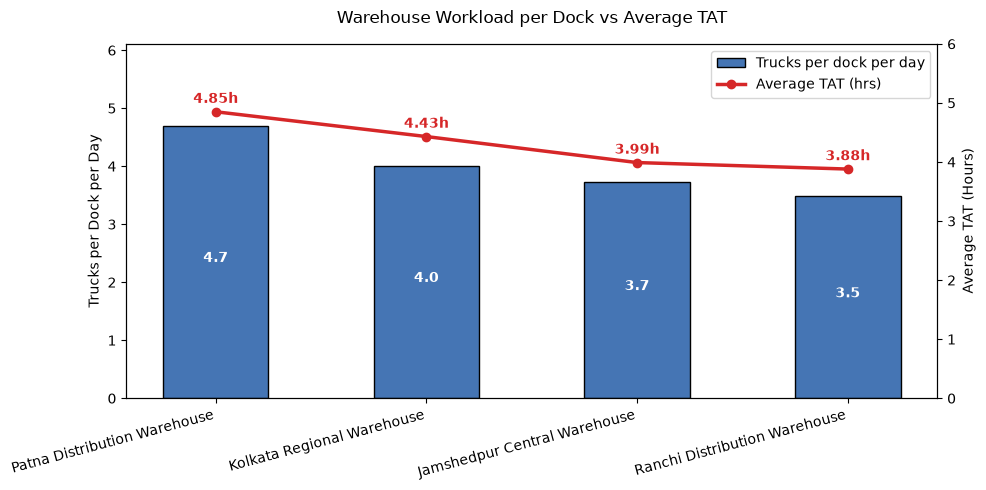

Docks used in data : {'WH01': 4, 'WH02': 3, 'WH03': 5, 'WH04': 3}




,dock_id,warehouse_id,dock_name,dock_type
0,WH01_D01,WH01,Dock 01,Inbound
1,WH01_D02,WH01,Dock 02,Outbound
2,WH01_D03,WH01,Dock 03,Inbound
3,WH01_D04,WH01,Dock 04,Outbound
4,WH02_D01,WH02,Dock 01,Inbound


In [25]:


OPERATING_HOURS = 24  
PEAK_HOURS = [10, 11, 14, 15]

wl = df_clean.merge(df_warehouse, on='warehouse_id', how='left').copy()

wl['dock_occupied_min'] = wl['dock_wait_min'] + wl['loading_unloading_min']
wl['is_peak'] = wl['arrival_hour'].isin(PEAK_HOURS)

g = wl.groupby(['warehouse_id', 'warehouse_name'])
workload = g.agg(
    trucks=('truck_visit_id', 'count'),
    active_days=('arrival_date', 'nunique'),
    docks_used=('dock_id', 'nunique'),
    total_tons=('load_tons', 'sum'),
    total_cases=('cases_handled', 'sum'),
    avg_tons_per_truck=('load_tons', 'mean'),
    avg_loading_min=('loading_unloading_min', 'mean'),
    dock_occupied_min=('dock_occupied_min', 'sum'),
    peak_share_pct=('is_peak', 'mean'),
    avg_dock_wait_min=('dock_wait_min', 'mean'),
    avg_tat_hrs=('calculated_tat_hours', 'mean'),
).reset_index()

# Derived workload metrics
workload['trucks_per_day'] = workload['trucks'] / workload['active_days']
workload['trucks_per_dock_per_day'] = workload['trucks_per_day'] / workload['docks_used']
workload['tons_per_dock_per_day'] = workload['total_tons'] / workload['active_days'] / workload['docks_used']
workload['dock_utilisation_pct'] = (workload['dock_occupied_min'] /
    (workload['docks_used'] * workload['active_days'] * OPERATING_HOURS * 60)) * 100
workload['peak_share_pct'] *= 100

workload = workload.round(2).sort_values('avg_tat_hrs', ascending=False)   # Analysis 5 jaisa order

cols = ['warehouse_id', 'warehouse_name', 'docks_used', 'trucks', 'trucks_per_day',
        'trucks_per_dock_per_day', 'tons_per_dock_per_day', 'dock_utilisation_pct',
        'peak_share_pct', 'avg_dock_wait_min', 'avg_tat_hrs']
display(workload[cols])

# Comparison chart: workload per dock (bars) vs average TAT (line)
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(workload))
bars = ax1.bar(x, workload['trucks_per_dock_per_day'], color='#4575b4', edgecolor='black', width=0.5,
               label='Trucks per dock per day')
ax1.set_xticks(x)
ax1.set_xticklabels(workload['warehouse_name'], rotation=15, ha='right')
ax1.set_ylabel('Trucks per Dock per Day')
ax1.set_ylim(0, workload['trucks_per_dock_per_day'].max() * 1.3)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h * 0.5, f"{h:.1f}", ha='center', color='white', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(x, workload['avg_tat_hrs'], color='#d62728', marker='o', linewidth=2.5, label='Average TAT (hrs)')
ax2.set_ylabel('Average TAT (Hours)')
ax2.set_ylim(0, 6)
for xi, yi in zip(x, workload['avg_tat_hrs']):
    ax2.text(xi, yi + 0.15, f"{yi:.2f}h", ha='center', color='#d62728', fontweight='bold')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right')
plt.title('Warehouse Workload per Dock vs Average TAT', pad=15)
plt.tight_layout()
plt.show()

# Sanity check: kitne docks data mein use hue vs dock master mein
print("Docks used in data :", wl.groupby('warehouse_id')['dock_id'].nunique().to_dict())
print("\n")
df_dock.head()

**Business Insight:**
* Turnaround time differs clearly across facilities: **Patna Distribution (4.85h)**, **Kolkata Regional (4.43h)**, **Jamshedpur Central (3.99h)** and **Ranchi Distribution (3.88h)**.
* The ranking follows the **workload per dock**: Patna handles **4.7 trucks per dock per day** (3 docks, estimated utilisation 74% of a 24-hour dock day, average dock wait 117 minutes), while Ranchi handles **3.5** (utilisation 41%, dock wait 60 minutes). Kolkata (4.0) and Jamshedpur (3.7) sit in between, and TAT and dock wait fall in the same order across all four sites.
* Utilisation is measured on a 24-hour day, but trucks arrive only between 08:00 and 19:59, so during working hours the docks are much busier than these percentages suggest. Dock capacity per site is therefore a real constraint, and Patna (3 docks, highest load per dock) is the first candidate for extra capacity or slot control.


### Analysis 6: Truck Arrival Patterns & Gate Peak Hours
**Business Question:** At what hours of the day do truck arrivals surge, causing gate and dock congestion?


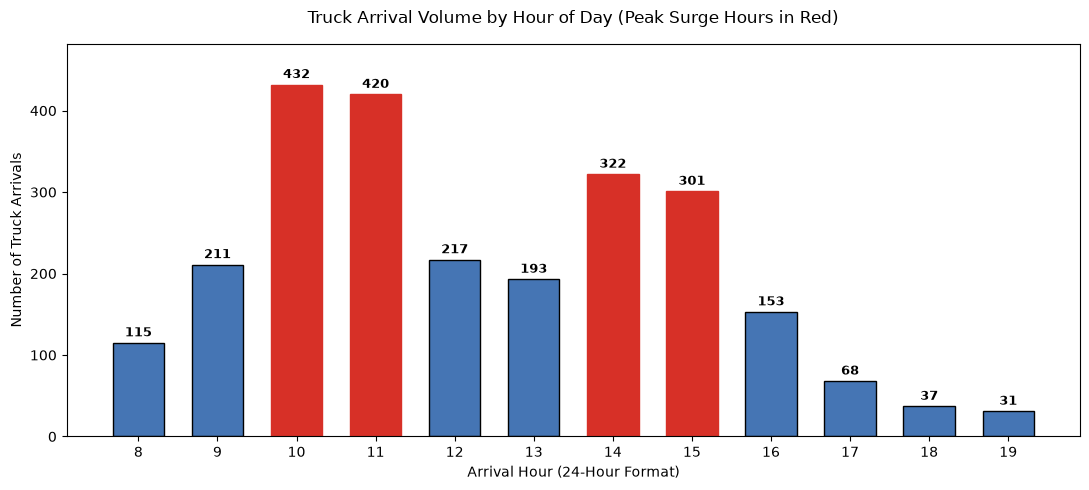

In [26]:
hourly_counts = df_clean['arrival_hour'].value_counts().sort_index()

plt.figure(figsize=(11, 5))
bars = plt.bar(hourly_counts.index, hourly_counts.values, color='#4575b4', edgecolor='black', width=0.65)

# Highlight high-volume peak arrival hours in red
for bar, hr in zip(bars, hourly_counts.index):
    if hr in [10, 11, 14, 15]:
        bar.set_color('#d73027')

plt.title('Truck Arrival Volume by Hour of Day (Peak Surge Hours in Red)', pad=15)
plt.xlabel('Arrival Hour (24-Hour Format)')
plt.ylabel('Number of Truck Arrivals')
plt.xticks(hourly_counts.index)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 8, f"{h}", ha='center', fontsize=9, fontweight='bold')

plt.ylim(0, hourly_counts.max() + 50)
plt.tight_layout()
plt.show()


**Business Insight:**
* Inbound arrivals exhibit two clear volume surges: **Morning Peak (10:00 - 11:59)** with **852 trucks (34.1% of total volume)**, and **Afternoon Peak (14:00 - 15:59)** with **623 trucks (24.9% of total volume)**.
* Combined, **59.0% of all trucks (1,475)** arrive within two narrow 2-hour windows.
* Dock wait is almost the same for peak (85.0 min) and off-peak (82.5 min) arrivals, but the hourly chart shows why: the queue **builds through the day and lags the arrival peaks**. Average dock wait is only about **28 minutes for 08:00 - 09:59 arrivals**, stays around 95 to 110 minutes from midday to 15:59 and reaches its maximum of **135 minutes for 17:00 arrivals**, because the morning surge fills the docks and the backlog is carried into the afternoon. The peak flag alone (based on arrival hour) therefore misses the real congestion window.


                              gate_to_dock_min  dock_wait_min  \
Off-peak arrivals                        19.29          82.50   
Peak arrivals (10-11, 14-15)             24.97          84.96   

                              calculated_tat_hours  
Off-peak arrivals                             4.21  
Peak arrivals (10-11, 14-15)                  4.40  


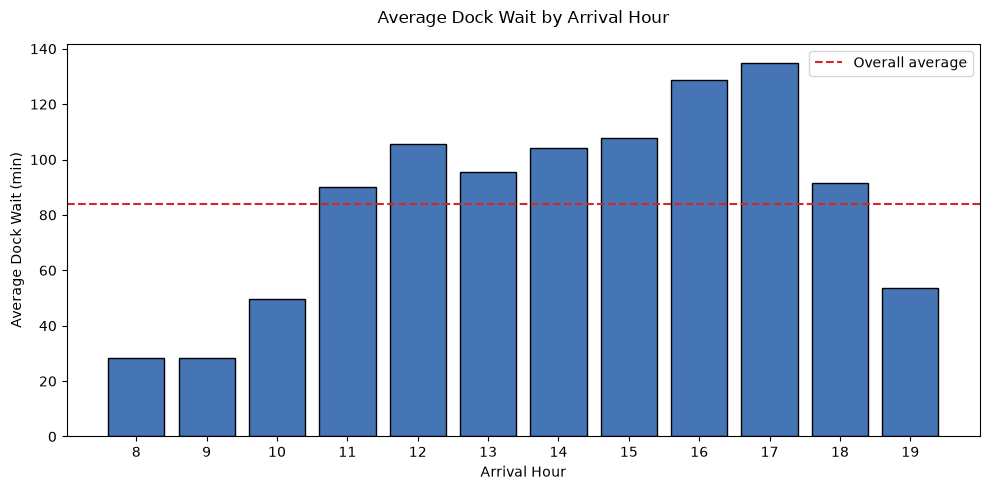

In [27]:
peak_compare = df_clean.groupby('is_peak')[['gate_to_dock_min', 'dock_wait_min', 'calculated_tat_hours']].mean().round(2)
peak_compare.index = ['Off-peak arrivals', 'Peak arrivals (10-11, 14-15)']
print(peak_compare)

hourly_wait = df_clean.groupby('arrival_hour')['dock_wait_min'].mean()
plt.figure(figsize=(10, 5))
plt.bar(hourly_wait.index, hourly_wait.values, color='#4575b4', edgecolor='black')
plt.axhline(df_clean['dock_wait_min'].mean(), color='#d62728', linestyle='--', label='Overall average')
plt.xticks(hourly_wait.index)
plt.xlabel('Arrival Hour')
plt.ylabel('Average Dock Wait (min)')
plt.title('Average Dock Wait by Arrival Hour', pad=15)
plt.legend()
plt.tight_layout()
plt.show()

### Analysis 7: Delay Root-Cause Breakdown
**Business Question:** What are the most common reported reasons for operational delays during truck visits?


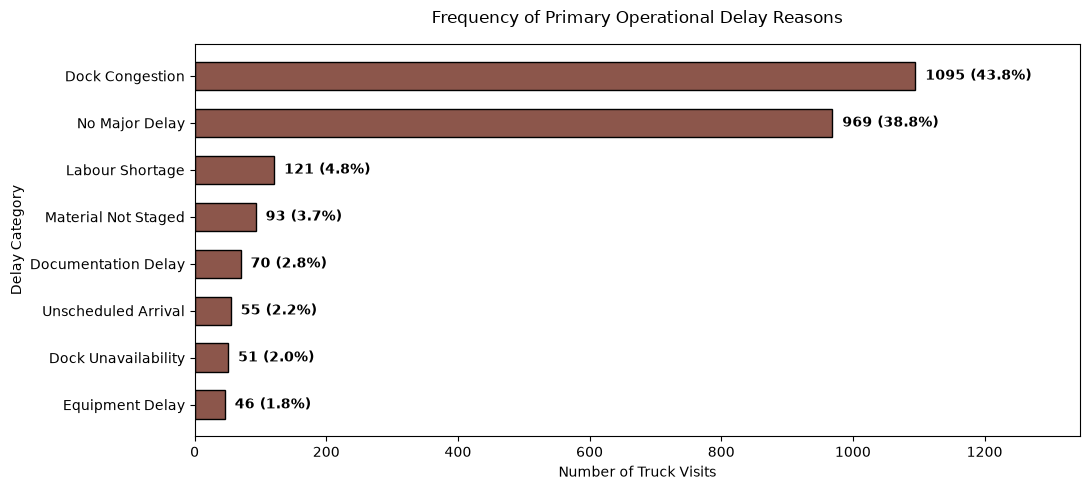

In [28]:
delay_counts = df_clean['primary_delay_reason'].value_counts()

plt.figure(figsize=(11, 5))
bars = plt.barh(delay_counts.index, delay_counts.values, color='#8c564b', edgecolor='black', height=0.6)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 15, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(df_clean)*100:.1f}%)", 
             va='center', fontweight='bold')

plt.title('Frequency of Primary Operational Delay Reasons', pad=15)
plt.xlabel('Number of Truck Visits')
plt.ylabel('Delay Category')
plt.xlim(0, delay_counts.max() + 250)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Business Insight:**
* **969 visits (38.8%)** were logged without a singular recorded delay. Among the **1,531 flagged trips (61.2%)**, the top reasons are:
  1. **Dock Congestion:** 1,095 trips (71.5% of flagged delays), by far the most frequent reason.
  2. **Labour Shortage:** 121 trips (7.9%)
  3. **Material Not Staged:** 93 trips (6.1%)
  4. **Documentation Delay:** 70 trips (4.6%)
  5. **Unscheduled Arrival, Dock Unavailability and Equipment Delay:** 55, 51 and 46 trips (3.6%, 3.3% and 3.0%)
* Dock Congestion is also the most costly reason: **1,095 trucks lost about 2.35 hours each against the baseline, 2,573 truck-hours in total**, far more than any other single reason (the next largest are Material Not Staged with 119 hours and Labour Shortage with 108 hours).
* Together the **dock-wait group (Dock Congestion, Dock Unavailability, Unscheduled Arrival) accounts for about 2,707 of the roughly 3,053 extra truck-hours (88.7%)**, followed by loading-related reasons (about 273 hours, 8.9%) and documentation (about 73 hours, 2.4%).
* The trips with no recorded delay average **3.10 hours**, which is close to the 3.0-hour target, although **52.7% of them still exceed it**. The baseline process therefore has little slack and the logged delays, mainly dock congestion, create most of the gap.


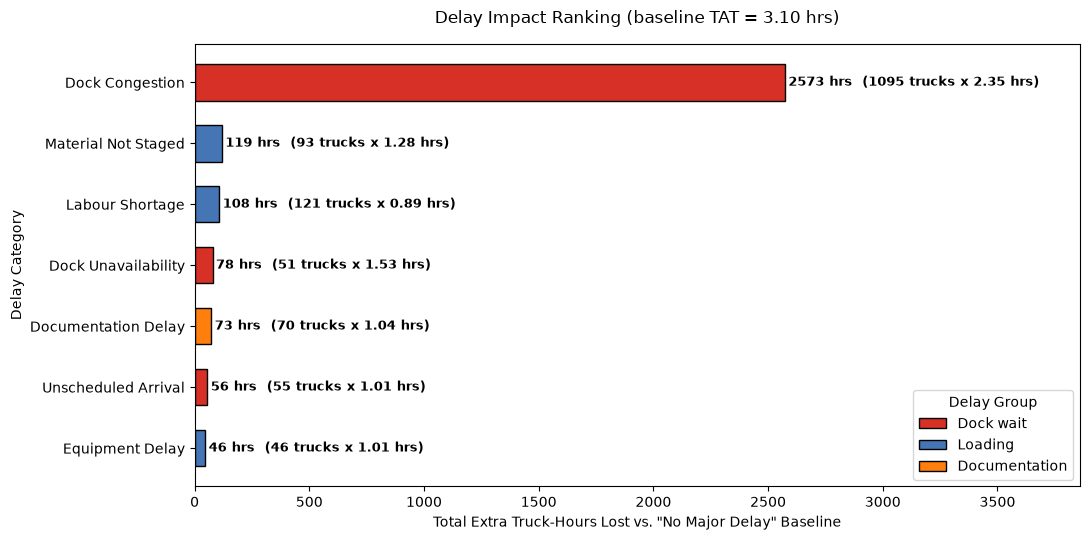

In [29]:
baseline = df_clean.loc[df_clean['primary_delay_reason'] == 'No Major Delay', 'calculated_tat_hours'].mean()

impact = (df_clean[df_clean['primary_delay_reason'] != 'No Major Delay']
          .groupby('primary_delay_reason')['calculated_tat_hours']
          .agg(trucks='count', avg_tat='mean').reset_index())
impact['extra_hrs_per_truck'] = (impact['avg_tat'] - baseline).round(2)
impact['total_extra_truck_hrs'] = (impact['trucks'] * impact['extra_hrs_per_truck']).round(1)
impact = impact.sort_values('total_extra_truck_hrs', ascending=True)  


group_map = {
    'Dock Unavailability': 'Dock wait', 'Unscheduled Arrival': 'Dock wait', 'Dock Congestion': 'Dock wait',
    'Labour Shortage': 'Loading', 'Material Not Staged': 'Loading', 'Equipment Delay': 'Loading',
    'Documentation Delay': 'Documentation'
}
group_colors = {'Dock wait': '#d73027', 'Loading': '#4575b4', 'Documentation': '#ff7f0e'}
colors = [group_colors[group_map[r]] for r in impact['primary_delay_reason']]

fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.barh(impact['primary_delay_reason'], impact['total_extra_truck_hrs'],
               color=colors, edgecolor='black', height=0.6)

for bar, (_, row) in zip(bars, impact.iterrows()):
    w = bar.get_width()
    
    ax.text(w + 15, bar.get_y() + bar.get_height() / 2,
            f"{w:.0f} hrs  ({int(row['trucks'])} trucks x {row['extra_hrs_per_truck']:.2f} hrs)",
            va='center', fontweight='bold', fontsize=9.5)

ax.set_xlim(0, impact['total_extra_truck_hrs'].max() * 1.5)
ax.set_xlabel('Total Extra Truck-Hours Lost vs. "No Major Delay" Baseline')
ax.set_ylabel('Delay Category')
ax.set_title(f'Delay Impact Ranking (baseline TAT = {baseline:.2f} hrs)', pad=15)

# Legend (group ke hisaab se)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=c, edgecolor='black', label=g) for g, c in group_colors.items()],
          title='Delay Group', loc='lower right')

plt.tight_layout()
plt.show()

### Analysis 8: Transporter Performance Comparison
**Business Question:** How does turnaround time differ across transport partners, and do contract carriers outperform spot market transporters?


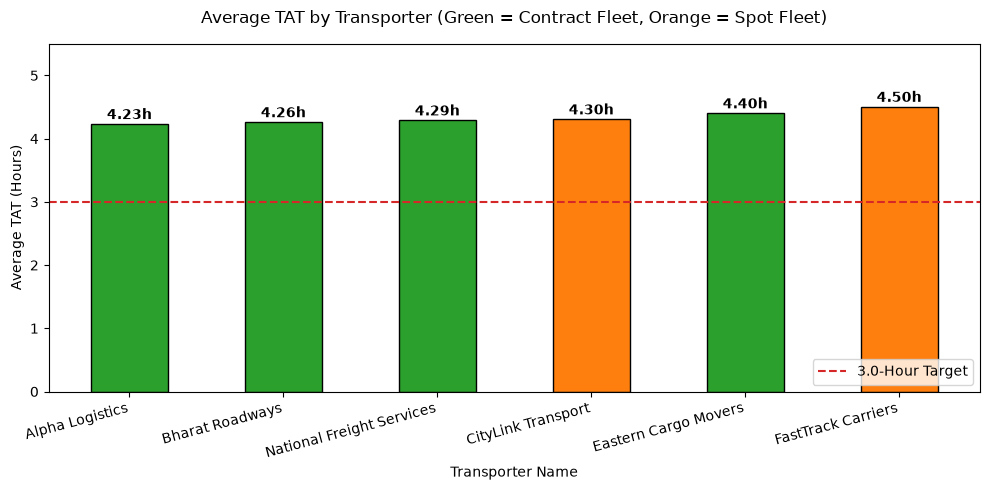

In [30]:
tr_merged = df_clean.merge(df_transporter, on='transporter_id', how='left')
tr_comparison = tr_merged.groupby(['transporter_id', 'transporter_name', 'contract_type', 'fleet_category'])['calculated_tat_hours'].agg(['mean', 'count']).reset_index()
tr_comparison = tr_comparison.sort_values(by='mean', ascending=True)

plt.figure(figsize=(10, 5))
palette = {'Contract': '#2ca02c', 'Spot': '#ff7f0e'}
bars = plt.bar(tr_comparison['transporter_name'], tr_comparison['mean'], 
               color=[palette[ct] for ct in tr_comparison['contract_type']], 
               edgecolor='black', width=0.5)

plt.axhline(3.0, color='#d62728', linestyle='--', linewidth=1.5, label='3.0-Hour Target')

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 0.08, f"{h:.2f}h", ha='center', fontweight='bold')

plt.title('Average TAT by Transporter (Green = Contract Fleet, Orange = Spot Fleet)', pad=15)
plt.xlabel('Transporter Name')
plt.ylabel('Average TAT (Hours)')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 5.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Business Insight:**
* **FastTrack Carriers (Spot, 4.50 hrs)** shows the highest turnaround time, followed by **Eastern Cargo Movers (Contract, 4.40 hrs)** and **CityLink Transport (Spot, 4.30 hrs)**. The best performers are **Alpha Logistics (4.23 hrs)**, **Bharat Roadways (4.26 hrs)** and **National Freight Services (4.29 hrs)**, all contract carriers.
* On average, spot carriers take **4.40 hours against 4.29 hours for contract carriers**, a gap of only about **6 minutes**. The difference is not statistically significant (Welch t-test, p = 0.12), and one contract carrier (Eastern Cargo Movers) is slower than one spot carrier (CityLink), so contract type does not separate good and bad performers in this data.
* The data does not record causes at carrier level, so gate-registration delays or unfamiliarity with yard protocols remain possible explanations, not proven ones. Turnaround is driven mainly by dock queues, which affect all carriers alike.


---
## PART G: Key Operational Findings

Based on 2,500 validated truck visits across four distribution centers, the analysis points to seven findings. Together they show that the TAT problem comes mainly from **dock queues** (dock capacity and dock allocation), with loading time as the second large block and gate, documentation and carrier type playing smaller roles.

1. **Severe Benchmark Compliance Deficit:**
   * Only **21.08% (527 trucks)** meet the 3.0-hour target. **78.92% (1,973 trucks)** exceed it, with an average TAT of **4.32 hours (259 minutes)**. Closing the gap needs roughly **79 minutes saved per truck**.

2. **Logged Delays, Mainly Dock Congestion, Create Most of the Gap:**
   * **969 visits (38.8%)** have no recorded delay reason, and their average TAT is **3.10 hours**, only a few minutes above the target (**52.7%** of them still exceed 3 hours). The standard process is therefore close to the benchmark but has no slack.
   * **61.2% of visits** carry a logged delay, and **71.5% of those are Dock Congestion**. Removing logged delays would bring the network average close to 3.1 hours.

3. **Time Is Spent Mainly in Loading and Dock Waiting:**
   * Average stage times: gate-to-dock **22.6 min (9%)**, dock wait **84.0 min (32%)**, loading/unloading **111.6 min (43%)**, documentation **32.6 min (13%)**, exit **8.6 min (3%)**.
   * Loading is the largest stage and depends on the load handled (correlation of loading time with cases handled is 0.89). Dock wait is the largest **non-value-added** stage (truck waiting, no material handling) and offers the biggest scope for reduction.

4. **Dock Capacity and Dock Allocation Are a Real Constraint:**
   * **59.3% of trucks (1,482)** were assigned to a dock that was still occupied by the previous truck. They waited **125.1 minutes** on average, against **24.0 minutes** for trucks whose dock was free (median 104 vs 15 minutes). The gap remains (48.8 vs 21.9 minutes) when dock-related delay reasons are excluded.
   * Workload per dock ranges from 3.5 (Ranchi) to 4.7 (Patna) trucks per dock per day, and TAT and dock wait rise in the same order (Patna 4.85 hrs and 117 min, Ranchi 3.88 hrs and 60 min).
   * The dock simulation shows that sending each truck to the first free dock in its warehouse would reduce average dock wait from **84.0 to 45.8 minutes**, TAT from 4.32 to **3.69 hours** and compliance from 21.1% to **36.1%**. Better dock allocation helps a lot, but it alone does not reach the 3.0-hour target.

5. **Arrival Peaking Builds a Queue That Peaks in the Afternoon:**
   * **59.0% of trucks (1,475)** arrive in four peak hours (10-11 and 14-15). Dock wait for peak arrivals (**85.0 min**) is almost equal to off-peak arrivals (**82.5 min**), but dock wait rises from about **28 minutes** (08:00-09:59 arrivals) to **135 minutes** (17:00 arrivals) as the morning surge is carried into the afternoon.
   * Time-slot booking and staggered arrivals should therefore flatten the build-up, and the afternoon window (12:00-18:00) is the most valuable one to target.

6. **Dock Congestion Dominates the Impact Ranking:**
   * By total extra truck-hours versus the no-delay baseline: Dock Congestion (**2,573 hrs**), Material Not Staged (**119.0**), Labour Shortage (**107.7**), Dock Unavailability (**78.0**), Documentation Delay (**72.8**), Unscheduled Arrival (**55.6**), Equipment Delay (**46.5**).
   * **Dock-wait related reasons together (about 2,707 hrs, 88.7%)** are the largest group, followed by loading-related reasons (about 273 hrs) and documentation (about 73 hrs). Here the most frequent reason (Dock Congestion) is also the most costly one.

7. **Contract vs. Spot Transporter Gap Is Small:**
   * Spot carriers average 4.40 hrs against 4.29 hrs for contract carriers, a gap of about 6 minutes that is not statistically significant (p = 0.12). The data does not record carrier-level causes.

**Data Limitations:**
* The dataset is synthetic/sample data generated with a yard-queue simulation (2,500 visits on 42 sampled operating days, about 60 trucks per day across the network), calibrated to an average dock wait of about 84 minutes. The relationships found (dock busy vs free, workload per dock, hourly queue build-up) therefore reflect the assumptions of the simulation and should be validated on real warehouse data.
* The 3.0-hour target is the dataset's own On Target threshold and is treated as the benchmark.
* Monthly figures are based on 7 sampled operating days each, so they show volume differences between those days and not a long-term trend.
* Dock utilisation is calculated on a 24-hour dock day, which understates utilisation during the actual 08:00-20:00 working window.


## optimisation model


# layer 1 

In [31]:
df_clean['dock_key'] = df_clean['warehouse_id'] + '_' + df_clean['dock_id']

d = df_clean.sort_values(['dock_key', 'dock_assigned_time']).copy()
d['dock_free_from'] = d.groupby('dock_key')['loading_end_time'].transform(lambda s: s.shift().cummax())
d['dock_was_busy'] = d['dock_free_from'] > d['dock_assigned_time']

dock_test = d.groupby('dock_was_busy')['dock_wait_min'].agg(['count', 'mean', 'median']).round(1)
dock_test.index = ['Dock was FREE', 'Dock was BUSY']
print(dock_test)
print("Trucks whose dock was free: %.0f%%" % (100 * (~d['dock_was_busy']).mean()))

               count   mean  median
Dock was FREE   1018   24.0    15.0
Dock was BUSY   1482  125.1   104.0
Trucks whose dock was free: 41%


In [32]:
n_docks = df_clean.groupby('warehouse_id')['dock_id'].nunique()

sim = df_clean.copy()
sim['day'] = sim['arrival_time'].dt.normalize()

sim['ready_min'] = (sim['dock_assigned_time'] - sim['day']).dt.total_seconds() / 60

sim_wait = {}
for (wh, day), g in sim.groupby(['warehouse_id', 'day']):      
    g = g.sort_values('ready_min')                              # jo pehle pahuncha, wo pehle
    dock_free_at = [0.0] * n_docks[wh]                          # shuru mein sab docks khali
    for idx, row in g.iterrows():
        k = dock_free_at.index(min(dock_free_at))               # sabse jaldi khali hone wala dock chuno
        start = max(row['ready_min'], dock_free_at[k])          # loading tab shuru jab truck aur dock dono ready
        sim_wait[idx] = start - row['ready_min']                # wait = shuru hone ka time - pahunchne ka time
        dock_free_at[k] = start + row['loading_unloading_min']  # ye dock ab loading khatam hone par free hoga

sim['sim_dock_wait_min'] = pd.Series(sim_wait)


other_min = sim['calculated_tat_hours'] * 60 - sim['dock_wait_min']
sim['sim_tat_hours'] = (other_min + sim['sim_dock_wait_min']) / 60

summary = pd.DataFrame({
    'Actual': [sim['dock_wait_min'].mean(), sim['calculated_tat_hours'].mean(),
               (sim['calculated_tat_hours'] <= 3).mean() * 100],
    'If only docks mattered': [sim['sim_dock_wait_min'].mean(), sim['sim_tat_hours'].mean(),
                               (sim['sim_tat_hours'] <= 3).mean() * 100]},
    index=['Avg dock wait (min)', 'Avg TAT (hrs)', 'Trucks within 3 hrs (%)']).round(2)
print(summary)

                         Actual  If only docks mattered
Avg dock wait (min)       83.95                   45.76
Avg TAT (hrs)              4.32                    3.69
Trucks within 3 hrs (%)   21.08                   36.12


### LAYER 2 

In [33]:
# Exit stage 
df_clean['exit_processing_min'] = (df_clean['exit_time'] - df_clean['documentation_complete_time']).dt.total_seconds() / 60

stages = {
    'Gate to dock':  'gate_to_dock_min',
    'Dock wait':     'dock_wait_min',
    'Loading':       'loading_unloading_min',
    'Documentation': 'documentation_min',
}
TARGET_MIN = 180   # 3.0 hours

stage_table = pd.DataFrame({
    'current_avg_min': {s: df_clean[c].mean() for s, c in stages.items()},
    'best_level_min':  {s: df_clean[c].quantile(0.25) for s, c in stages.items()},
})
stage_table['max_cut_min'] = stage_table['current_avg_min'] - stage_table['best_level_min']

total_avg_tat = df_clean[list(stages.values()) + ['exit_processing_min']].mean().sum()
required_cut = total_avg_tat - TARGET_MIN

print(stage_table.round(1))
print(f"\nCurrent average TAT : {total_avg_tat:.1f} min ({total_avg_tat/60:.2f} hrs)")
print(f"Target              : {TARGET_MIN} min")
print(f"Minutes to be saved : {required_cut:.1f} min per truck")
print(f"Maximum possible cut: {stage_table['max_cut_min'].sum():.1f} min")

               current_avg_min  best_level_min  max_cut_min
Gate to dock              22.6            15.0          7.6
Dock wait                 84.0            17.0         67.0
Loading                  111.6            82.0         29.6
Documentation             32.6            25.0          7.6

Current average TAT : 259.3 min (4.32 hrs)
Target              : 180 min
Minutes to be saved : 79.3 min per truck
Maximum possible cut: 111.7 min


In [34]:
from scipy.optimize import linprog

def solve_plan(costs, required_cut, max_cut):
    return linprog(c=costs, A_ub=[[-1] * len(costs)], b_ub=[-required_cut],
                   bounds=[(0, m) for m in max_cut], method='highs')


cost_scenarios = {
    'A: Base case':         [3, 1, 4, 2],     # [Gate, Dock wait, Loading, Documentation]
    'B: Loading is cheap':  [3, 1, 1.5, 2],
    'C: Dock wait is hard': [3, 5, 4, 2],
}

max_cut = stage_table['max_cut_min'].tolist()
plans = {}
for name, costs in cost_scenarios.items():
    res = solve_plan(costs, required_cut, max_cut)
    if res.success:
        plans[name] = list(res.x) + [res.fun]
    else:
        print(name, "-> target not reachable with these limits")

plan_table = pd.DataFrame(plans, index=list(stages.keys()) + ['TOTAL COST (units)']).T.round(1)
plan_table.columns = [f"{c} (min cut)" if c != 'TOTAL COST (units)' else c for c in plan_table.columns]
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
print(plan_table)

                      Gate to dock (min cut)  Dock wait (min cut)  Loading (min cut)  Documentation (min cut)  TOTAL COST (units)
A: Base case                             4.8                 67.0                0.0                      7.6                96.5
B: Loading is cheap                      0.0                 67.0               12.4                      0.0                85.5
C: Dock wait is hard                     7.6                 34.5               29.6                      7.6               329.1


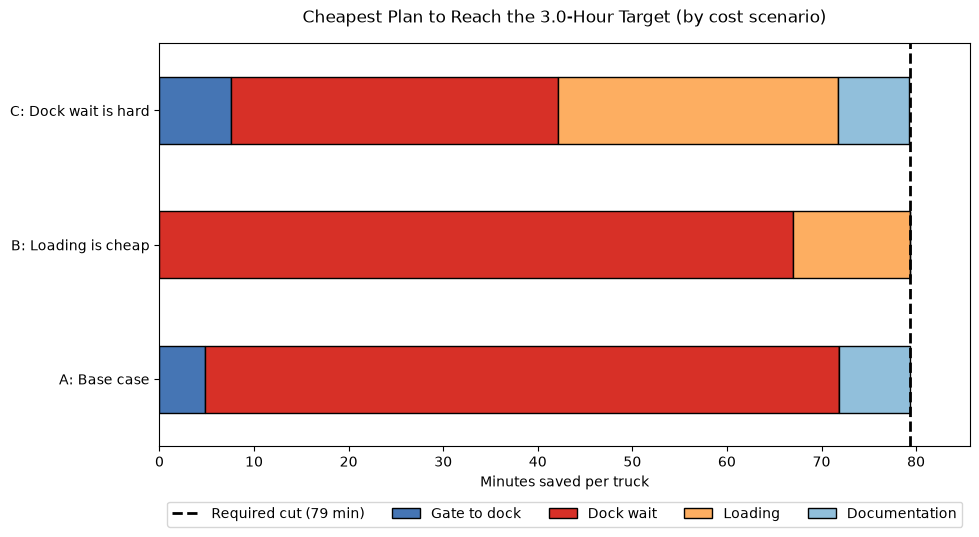

In [35]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plan_minutes = plan_table.drop(columns='TOTAL COST (units)')
plan_minutes.columns = list(stages.keys())
plan_minutes.plot(kind='barh', stacked=True, ax=ax, edgecolor='black',
                  color=['#4575b4', '#d73027', '#fdae61', '#91bfdb'])
ax.axvline(required_cut, color='black', linestyle='--', linewidth=2, label=f'Required cut ({required_cut:.0f} min)')
ax.set_xlabel('Minutes saved per truck')
ax.set_ylabel('')
ax.set_title('Cheapest Plan to Reach the 3.0-Hour Target (by cost scenario)', pad=15)
ax.set_xlim(0, required_cut * 1.08)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=True)
plt.tight_layout()
plt.show()

### INSIGHTS

Layer 1 Insight: **59.3% of trucks (1,482)** reached a dock that was still occupied and waited **125.1 minutes** on average, compared with **24.0 minutes** when the dock was free (median 104 vs 15 minutes). The difference stays large (48.8 vs 21.9 minutes) after removing the dock-related delay reasons, so the dock queue is a genuine driver of waiting. In the simulation where every truck goes to the first free dock of its warehouse, average dock wait falls from **84.0 to 45.8 minutes**, TAT from 4.32 to **3.69 hours** and compliance from 21.1% to **36.1%**. Better dock allocation recovers about 38 minutes per truck, but a queue remains even with ideal allocation, so extra dock capacity, slot booking and faster bay readiness are also needed to reach 3.0 hours.

Layer 2 Insight: The average truck needs to save **79 minutes** to reach the 3-hour target, while the maximum possible saving (bringing every stage to the best 25% level of the network itself) is **112 minutes**, so the target needs about **71%** of the maximum possible saving. Dock wait has the largest room for improvement (**67 minutes**, 60% of the maximum). The cheapest plans cut dock wait by its full 67 minutes in both the base case and the "loading is cheap" case, and use documentation, gate or loading only for the remaining 12 minutes. If dock wait is hard to reduce (scenario C), it can contribute only 34.5 minutes, every other stage must be cut to its limit and the plan cost rises to 329 units, about **3.4 times** the base-case cost (96.5 units).
